In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_csv("../data/processed/retail_inventory_cleaned.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (73100, 14)
Columns: ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Year,Month,DayOfWeek,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,2022,1,5,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,2022,1,5,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,2022,1,5,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,2022,1,5,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,2022,1,5,1030.96


In [2]:
prices_per_product = df.groupby("Product ID")["Price"].agg(
    observations="count",
    unique_prices="nunique",
    minimum_price="min",
    maximum_price="max",
    average_price="mean"
)

prices_per_product["price_range"] = (
    prices_per_product["maximum_price"]
    - prices_per_product["minimum_price"]
)

display(prices_per_product.head(10))

print(
    "Products with changing prices:",
    (prices_per_product["unique_prices"] > 1).sum()
)

print(
    "Products with constant prices:",
    (prices_per_product["unique_prices"] == 1).sum()
)

print("Total products:", len(prices_per_product))

,observations,unique_prices,minimum_price,maximum_price,average_price,price_range
Product ID,,,,,,
P0001,3655,3012,10.07,99.99,54.547330,89.92
P0002,3655,3033,10.01,99.99,55.267726,89.98
P0003,3655,2996,10.02,99.99,54.885759,89.97
P0004,3655,3036,10.01,99.98,55.538966,89.97
P0005,3655,3007,10.00,99.96,55.023590,89.96
P0006,3655,3035,10.00,99.97,54.767417,89.97
P0007,3655,3000,10.01,99.95,54.917921,89.94
P0008,3655,3007,10.03,99.98,55.349434,89.95
P0009,3655,3015,10.01,99.98,55.156235,89.97


Products with changing prices: 20
Products with constant prices: 0
Total products: 20


In [3]:
daily_summary = df.groupby("Date").agg(
    average_price=("Price", "mean"),
    average_units_sold=("Units Sold", "mean"),
    total_units_sold=("Units Sold", "sum"),
    observations=("Units Sold", "count")
).reset_index()

display(daily_summary.head())

,Date,average_price,average_units_sold,total_units_sold,observations
0,2022-01-01,57.5157,144.84,14484,100
1,2022-01-02,60.6365,134.15,13415,100
2,2022-01-03,56.7993,136.81,13681,100
3,2022-01-04,52.9930,140.84,14084,100
4,2022-01-05,55.9958,125.72,12572,100


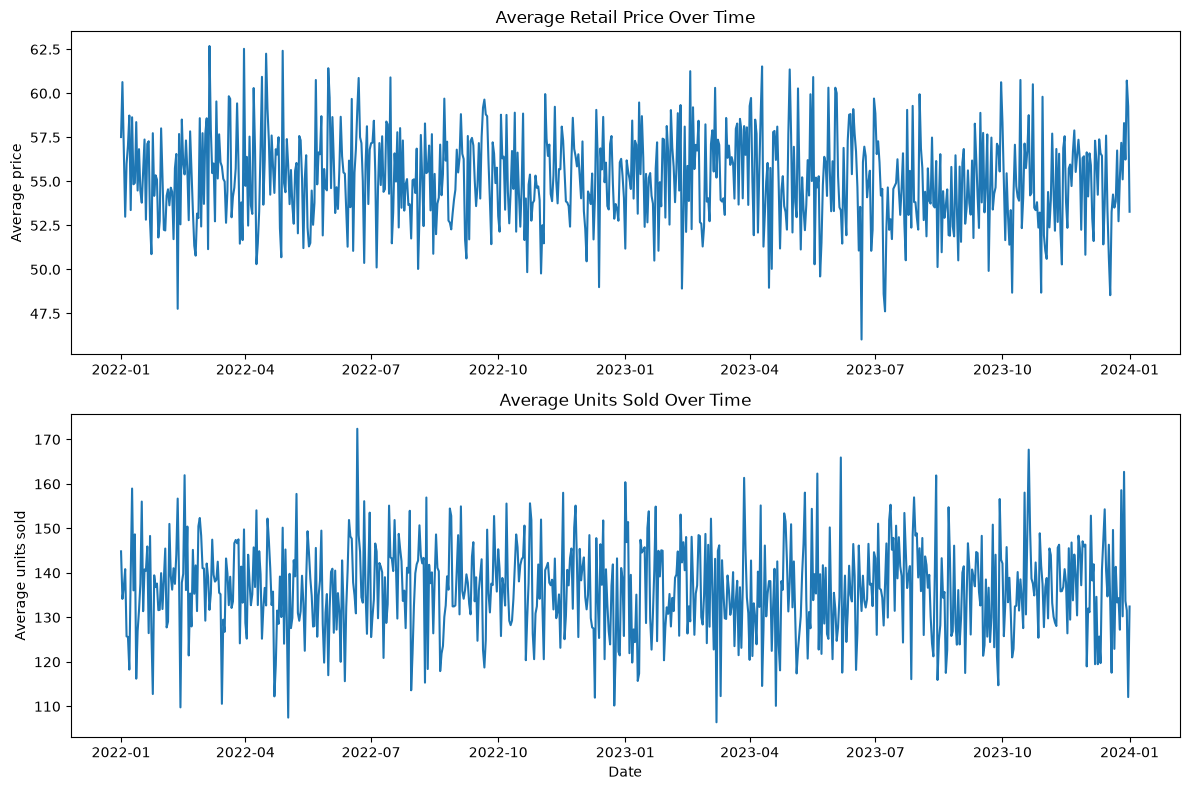

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(
    daily_summary["Date"],
    daily_summary["average_price"]
)
axes[0].set_title("Average Retail Price Over Time")
axes[0].set_ylabel("Average price")

axes[1].plot(
    daily_summary["Date"],
    daily_summary["average_units_sold"]
)
axes[1].set_title("Average Units Sold Over Time")
axes[1].set_ylabel("Average units sold")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [5]:
possible_controls = [
    "Inventory Level",
    "Demand Forecast",
    "Category",
    "Region",
    "Product ID",
    "Store ID",
    "Date",
    "Units Ordered"
]

for col in possible_controls:
    print(f"{col}: {col in df.columns}")

Inventory Level: True
Demand Forecast: True
Category: True
Region: True
Product ID: True
Store ID: True
Date: True
Units Ordered: True


In [6]:
available_controls = [
    col for col in possible_controls
    if col in df.columns
]

display(
    df[available_controls]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

Inventory Level    0
Demand Forecast    0
Category           0
Region             0
Product ID         0
Store ID           0
Date               0
Units Ordered      0
dtype: int64

In [7]:
product_correlations = df.groupby("Product ID").apply(
    lambda group: group["Price"].corr(group["Units Sold"])
    if (
        group["Price"].nunique() > 1
        and group["Units Sold"].nunique() > 1
    )
    else np.nan,
    include_groups=False
)

print("Product-level correlations:")
display(product_correlations.describe())

print(
    "Products with calculable correlations:",
    product_correlations.notna().sum()
)

Product-level correlations:


count    20.000000
mean      0.001092
std       0.019403
min      -0.024488
25%      -0.016706
50%      -0.002086
75%       0.019976
max       0.034087
dtype: float64

Products with calculable correlations: 20


In [8]:
product_correlations = df.groupby("Product ID").apply(
    lambda group: group[["Price", "Units Sold"]]
    .corr()
    .loc["Price", "Units Sold"]
    if (
        group["Price"].nunique() > 1
        and group["Units Sold"].nunique() > 1
    )
    else np.nan
)

display(product_correlations.describe())

count    20.000000
mean      0.001092
std       0.019403
min      -0.024488
25%      -0.016706
50%      -0.002086
75%       0.019976
max       0.034087
dtype: float64

In [9]:
total_products = df["Product ID"].nunique()

products_with_price_changes = (
    prices_per_product["unique_prices"] > 1
).sum()

print("Total observations:", len(df))
print("Total products:", total_products)
print("Products with price variation:", products_with_price_changes)

if total_products > 0:
    print(
        "Share of products with price variation:",
        round(products_with_price_changes / total_products * 100, 2),
        "%"
    )

print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Unique stores:", df["Store ID"].nunique())
print("Unique dates:", df["Date"].nunique())

Total observations: 73100
Total products: 20
Products with price variation: 20
Share of products with price variation: 100.0 %
Date range: 2022-01-01 00:00:00 to 2024-01-01 00:00:00
Unique stores: 5
Unique dates: 731
